# Accumulated area and reversal — saved-data figures

Use the same run as calcul.ipynb. Each defect has its own figure: two rows for the candidate groups and four columns for 10, 20, 40 and 80 cycles. Every panel compares both methods against step size. Shared logarithmic axes support comparison. Each box represents eight particle defects: quartiles, median, minimum–maximum whiskers and all individual values.

This notebook loads verified results and never integrates trajectories. All figure text is French.

In [1]:
from pathlib import Path
import json
import sys

# Locate the code repository from this section folder or its parent directories.
ROOT = next(
    (candidate.resolve()
     for parent in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     for candidate in (parent, parent / "GC2D_codigo")
     if (candidate / "src/studies/midpoint_geometry_sweep.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "GC2D_codigo was not found. Keep it beside TFM_redaccion "
        "or start the notebook from the code repository."
    )
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from studies.midpoint_geometry_sweep import RUN_ID, STUDY_PREFIX, COUNTS, HORIZONS
from diagnostics.studies.midpoint_geometry_sweep import verify_record, recover_record

RUN_DIRECTORY = ROOT / "outputs/midpoint_geometry" / RUN_ID
BUCKET = f"gc2d_data:gc2d-notebooks-data/{STUDY_PREFIX}/{RUN_ID}"


In [2]:
if not (RUN_DIRECTORY / "manifest.json").is_file():
    recover_record(BUCKET, RUN_DIRECTORY)
summary = verify_record(RUN_DIRECTORY)
assert summary["run_id"] == RUN_ID
print("Loaded:", summary["run_id"])


Loaded: midpoint-jacobian-product-20261122-rho0015


## Export and inspect the two figures

The shared script independently validates raw arrays and group reductions, then exports PDF, PNG and provenance JSON. It does not open or render the thesis PDF.

Exported figure: simplecticidad_midpoint_acumulada_fr
Exported figure: simetria_midpoint_acumulada_fr



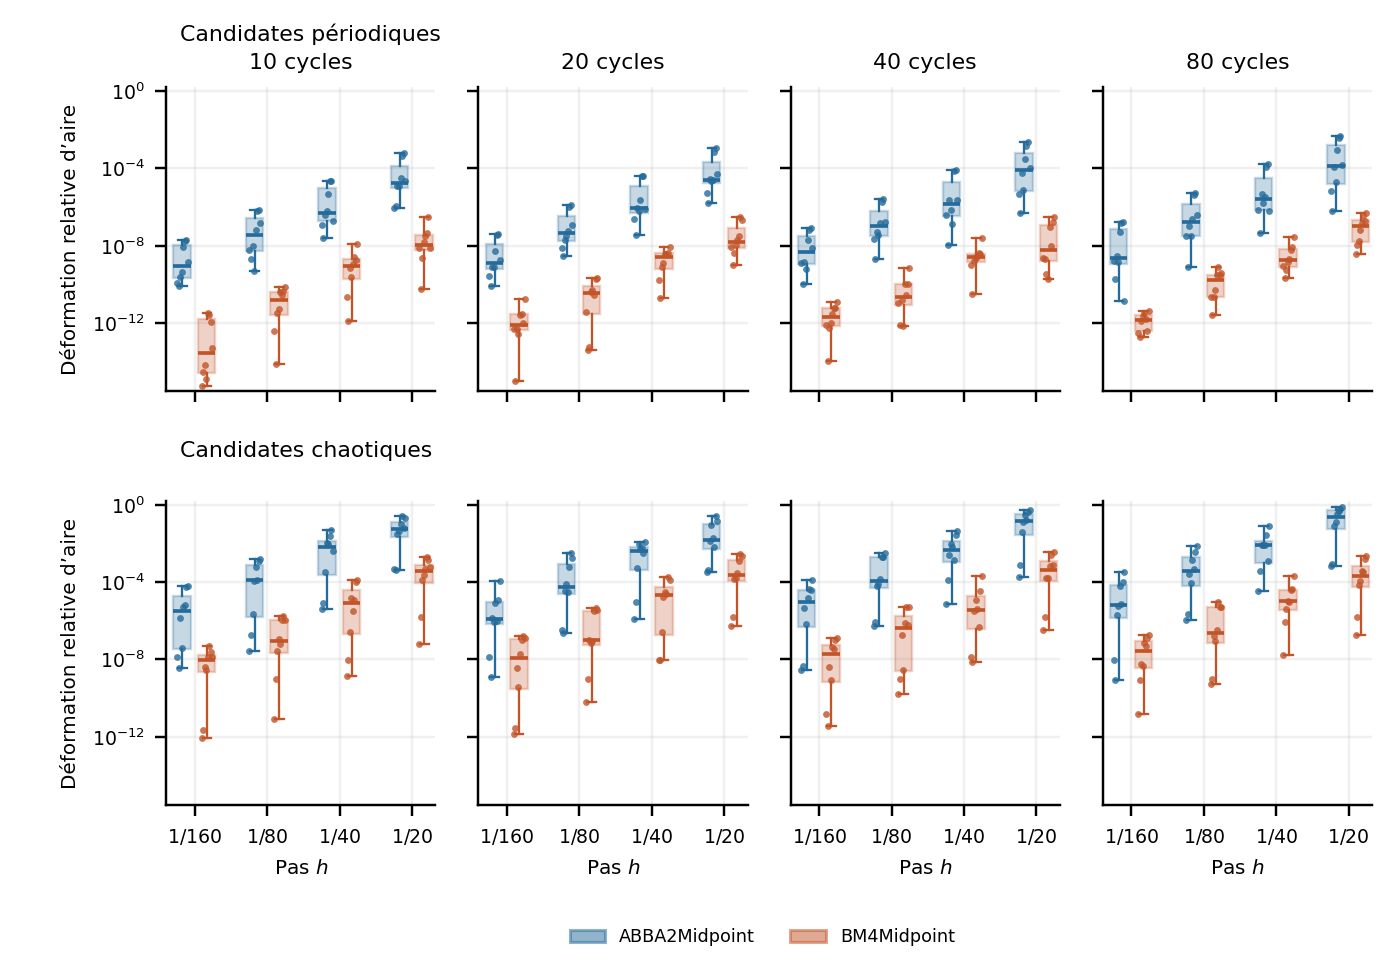

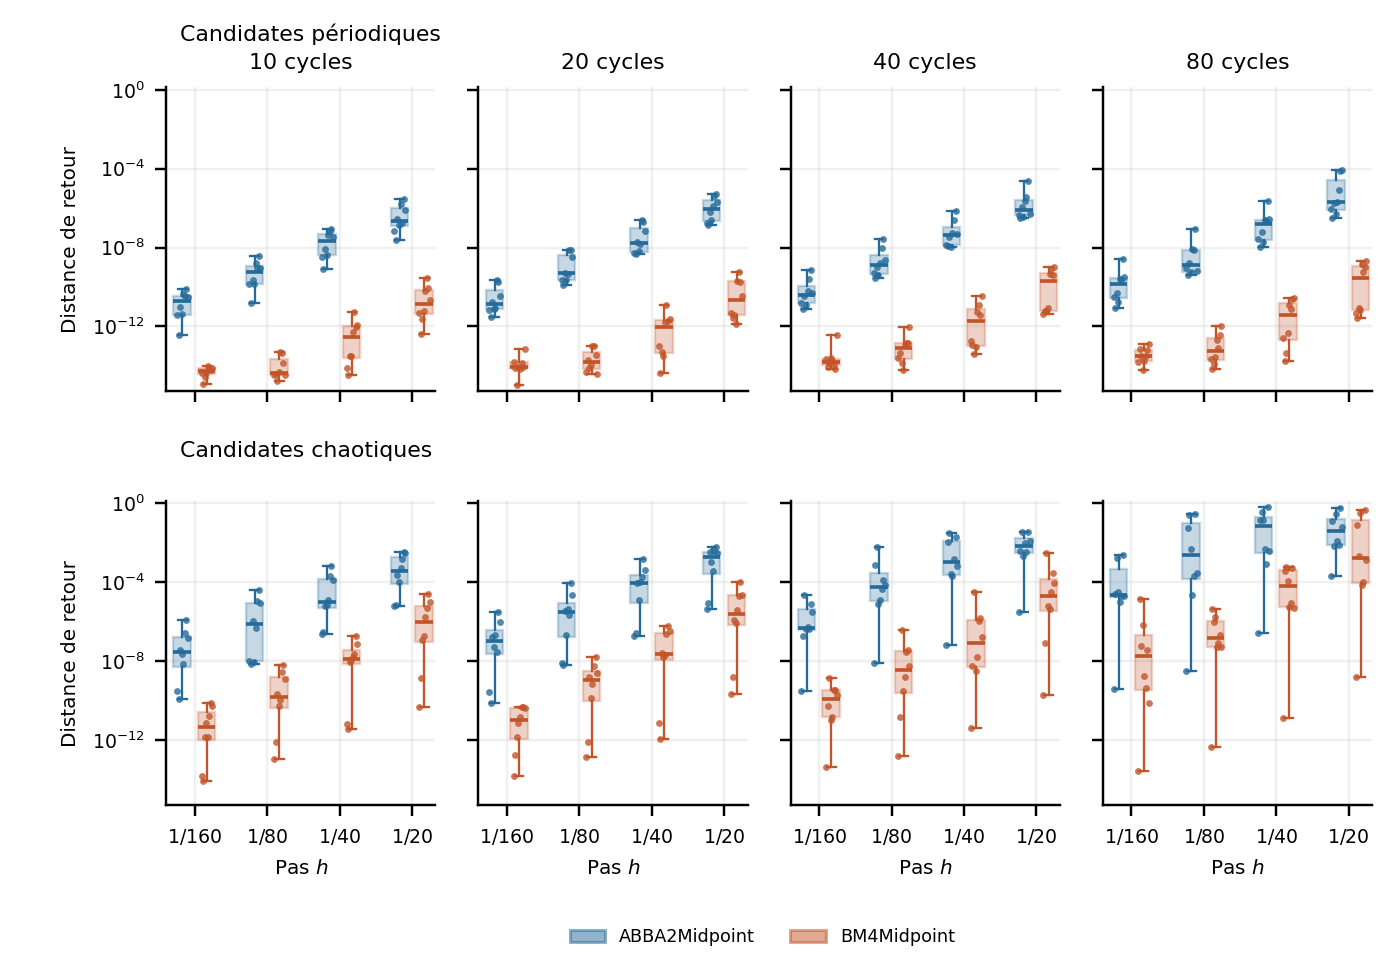

In [3]:
import subprocess
THESIS_ROOT = ROOT.parent / "TFM_redaccion"
completed = subprocess.run(
    [sys.executable, str(THESIS_ROOT / "notebooks/geometria_midpoint_barrido.py"),
     "--results", str(RUN_DIRECTORY)], cwd=THESIS_ROOT, check=True, capture_output=True, text=True)
print(completed.stdout.replace("Figura exportada:", "Exported figure:"))
from IPython.display import Image, display
for name in ("simplecticidad_midpoint_acumulada_fr", "simetria_midpoint_acumulada_fr"):
    display(Image(filename=str(THESIS_ROOT / "figuras" / (name + ".png"))))
